Data Distribution

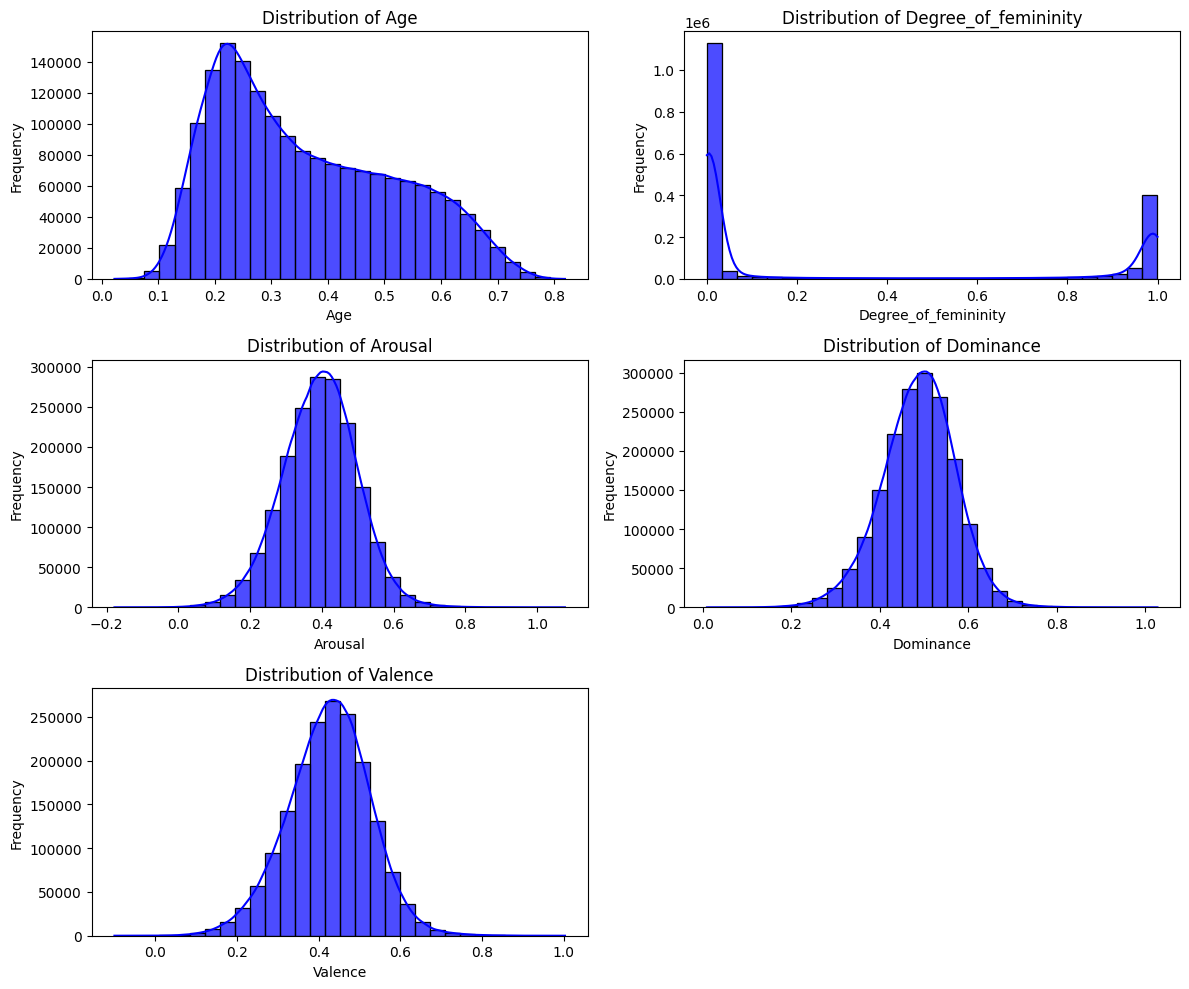

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Path to the CSV file
file_path = '/mnt/nvme-data1/waris/datasets/cv-corpus-16.1-2023-12-06/en/attributes/attributes.txt'  # Replace with your file name

# Load the data
columns = ['filename', 'age', 'degree_of_femininity', 'arousal', 'dominance', 'valence']
df = pd.read_csv(file_path, sep='|', header=None, names=columns)

# Convert values to numeric (if necessary)
df['age'] = pd.to_numeric(df['age'])
df['degree_of_femininity'] = pd.to_numeric(df['degree_of_femininity'])
df['arousal'] = pd.to_numeric(df['arousal'])
df['dominance'] = pd.to_numeric(df['dominance'])
df['valence'] = pd.to_numeric(df['valence'])

# Plot the distribution for each feature
features = ['age', 'degree_of_femininity', 'arousal', 'dominance', 'valence']
plt.figure(figsize=(12, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[feature], kde=True, bins=30, color='blue', alpha=0.7)
    plt.title(f'Distribution of {feature.capitalize()}')
    plt.xlabel(feature.capitalize())
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Anon vs Quality

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def load_and_process_data(file_path):
    # Load the CSV file
    df = pd.read_csv(file_path)

    # Extract lambda, cosine_sim, and P808_MOS mean and std
    df['cosine_sim_mean'] = df['cosine_sim'].str.split(' ± ').str[0].astype(float)
    df['cosine_sim_std'] = df['cosine_sim'].str.split(' ± ').str[1].astype(float)
    df['P808_MOS_mean'] = df['P808_MOS'].str.split(' ± ').str[0].astype(float)
    df['P808_MOS_std'] = df['P808_MOS'].str.split(' ± ').str[1].astype(float)

    lambda_values = df['lambda']
    cosine_mean = df['cosine_sim_mean']
    cosine_std = df['cosine_sim_std']
    p808_mean = df['P808_MOS_mean']
    p808_std = df['P808_MOS_std']
    
    return lambda_values, cosine_mean, cosine_std, p808_mean, p808_std

def create_plot(lambda_values, cosine_mean, cosine_std, p808_mean, p808_std):
    # Create the plot
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Plot cosine similarity
    ax1.plot(lambda_values, cosine_mean, label='Cosine Similarity', color='blue')
    ax1.fill_between(lambda_values, cosine_mean - cosine_std, cosine_mean + cosine_std, 
                     color='blue', alpha=0.2)
    ax1.set_xlabel('Lambda')
    ax1.set_ylabel('Cosine Similarity', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # Create a second y-axis for P808_MOS
    ax2 = ax1.twinx()
    ax2.plot(lambda_values, p808_mean, label='P808 MOS', color='orange')
    ax2.fill_between(lambda_values, p808_mean - p808_std, p808_mean + p808_std, 
                     color='orange', alpha=0.2)
    ax2.set_ylabel('P808 MOS', color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # Add legends and grid
    fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9))
    plt.title('Visualization of Cosine Similarity and P808 MOS vs Lambda')
    plt.grid()
    plt.tight_layout()
    
    return plt


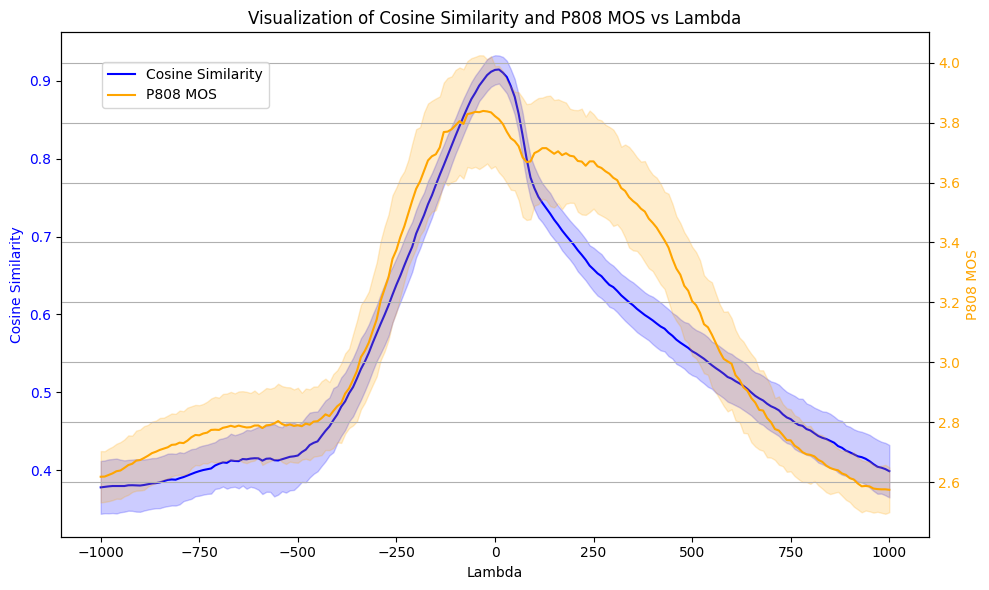

In [4]:
file_path = "results/RMS_lambda_embeds.csv"
lambda_values, cosine_mean, cosine_std, p808_mean, p808_std = load_and_process_data(file_path)

# Create and show the plot
plt = create_plot(lambda_values, cosine_mean, cosine_std, p808_mean, p808_std)

# Show the plot
plt.show()


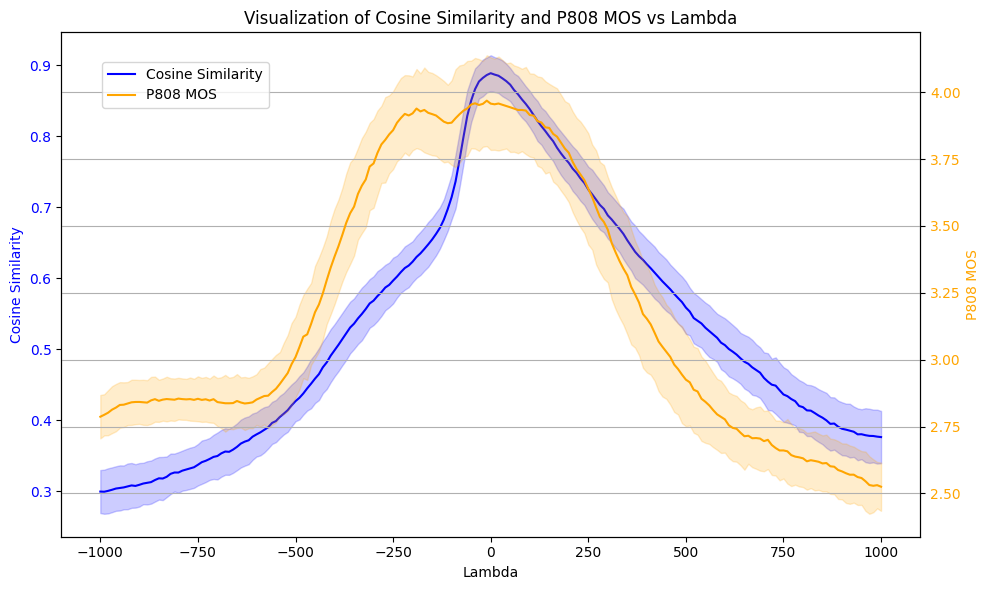

In [5]:
file_path = "results/SLT_lambda_embeds.csv"
lambda_values, cosine_mean, cosine_std, p808_mean, p808_std = load_and_process_data(file_path)

# Create and show the plot
plt = create_plot(lambda_values, cosine_mean, cosine_std, p808_mean, p808_std)

# Show the plot
plt.show()

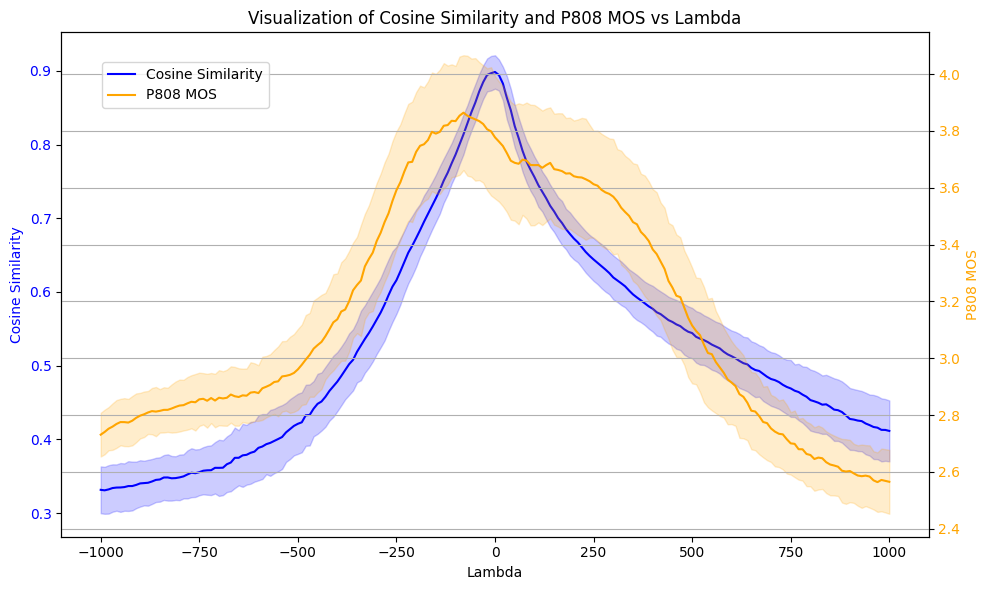

In [6]:
file_path = "results/BDL_lambda_embeds.csv"
lambda_values, cosine_mean, cosine_std, p808_mean, p808_std = load_and_process_data(file_path)

# Create and show the plot
plt = create_plot(lambda_values, cosine_mean, cosine_std, p808_mean, p808_std)

# Show the plot
plt.show()

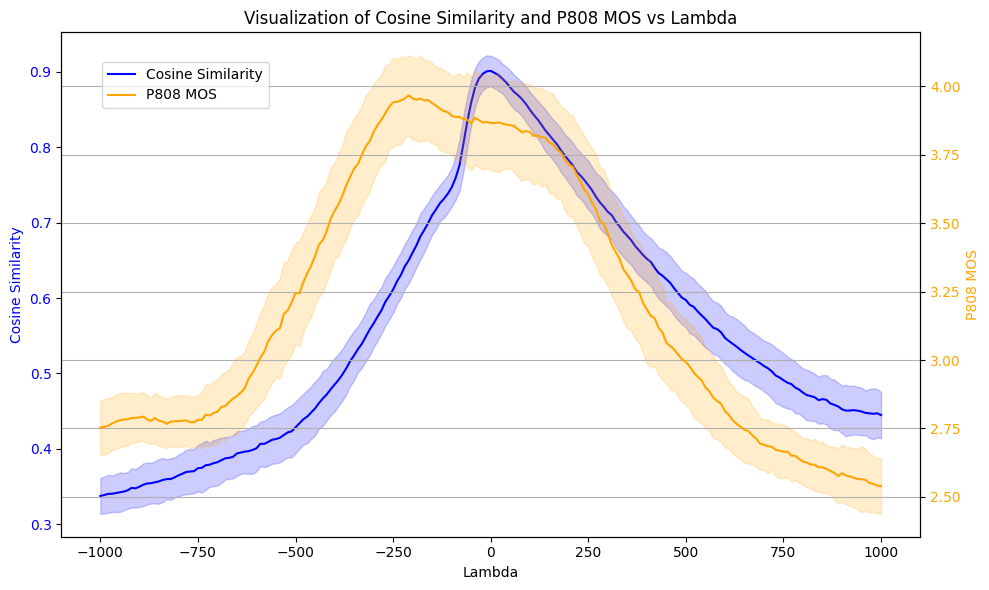

In [7]:
file_path = "results/CLB_lambda_embeds.csv"
lambda_values, cosine_mean, cosine_std, p808_mean, p808_std = load_and_process_data(file_path)

# Create and show the plot
plt = create_plot(lambda_values, cosine_mean, cosine_std, p808_mean, p808_std)

# Show the plot
plt.show()